# Demo: knee MRI in, 12 findings out

**RSNA Knee Abnormality Detection (Kaggle 2026) · Team 10 · Computer Vision course**

This notebook runs our **efficiency-track model** (CoAtNet-2 window-level attention MIL, folds 0 and 1, exactly the
2-checkpoint model we submitted) on three knee MRI studies, starting from the raw DICOM files.

* The three studies come from the **58 expert-labelled ("gold") studies**. No model was trained on them or selected
  with them, so the radiologists' labels are a fair check.
* They are picked by a **fixed rule on the expert labels**, written before any prediction was looked at (cell 3).
* For each study: decode → 12 probabilities next to the radiologists' labels → the slices the model attended to.

The public copy of this notebook hides the MRI images (competition data); the numbers are identical.

In [1]:
import hashlib, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

CODE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent  # repo root
sys.path[:0] = [str(CODE / "src"), str(CODE / "scripts")]
from rsna_knee import wmil                      # the same decode / window code as the Kaggle notebook
from viz_attention import attention_and_logits  # exposes the attention that produced each prediction

ROOT = Path(os.environ["RSNA_ROOT"]); ART, RAW = ROOT / "artifacts", ROOT / "data/raw"
SHOW_MRI = os.environ.get("DEMO_SHOW_MRI", "1") == "1"
T = wmil.TARGET_COLUMNS
SLOTS = ["Sagittal FS", "Sagittal", "Coronal FS", "Coronal", "Axial"]
DEV = "cuda"
pd.set_option("display.precision", 3)
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| show MRI images:", SHOW_MRI)

GPU: NVIDIA H100 80GB HBM3 | torch 2.4.0+cu121 | show MRI images: False


## 1. Load the model (2 checkpoints, as submitted to the efficiency track)

In [2]:
t = time.time()
models = []
for k in (0, 1):
    ck = torch.load(ART / f"exp018_coatnet2_wmil_v3labels/fold{k}/best.pt", map_location="cpu", weights_only=False)
    m = wmil.WindowMIL(ck["arch"], pretrained=False, grad_checkpointing=False)
    m.load_state_dict(ck["model"], strict=True)
    models.append(m.to(DEV).eval())
RES = int(ck["res"])
n_par = sum(p.numel() for p in models[0].parameters()) / 1e6
print(f"{ck['arch']}: {n_par:.1f} M parameters per checkpoint, input {RES} px, loaded in {time.time() - t:.1f} s")

coatnet_rmlp_2_rw_384.sw_in12k_ft_in1k: 73.1 M parameters per checkpoint, input 384 px, loaded in 8.1 s


## 2. Pick three gold studies by a fixed rule (expert labels only)

In [3]:
train = pd.read_csv(RAW / "train.csv").set_index("StudyInstanceUID")
gold = train.dropna(subset=T)[T].astype(int)
folds = pd.read_parquet(ART / "folds.parquet")
assert set(gold.index) == set(folds[folds.fold == -1].study_uid), "gold studies are the held-out fold -1"

g = gold.assign(h=[hashlib.md5(u.encode()).hexdigest() for u in gold.index]).sort_values("h")
acl = g[g["ACL"] == 1].index[0]
oa = g[(g["Medial OA"] == 1) & (g["ACL"] == 0)].index[0]
few = g[(g[T].sum(1) <= 1) & ~g.index.isin([acl, oa])].index[0]
chosen = {"Study 1: first ACL tear": acl, "Study 2: first medial OA without ACL tear": oa,
          "Study 3: first study with at most one finding": few}
print(len(gold), "gold studies; order = md5(StudyInstanceUID)")
for name in chosen:
    print(" ", name)

58 gold studies; order = md5(StudyInstanceUID)
  Study 1: first ACL tear
  Study 2: first medial OA without ACL tear
  Study 3: first study with at most one finding


## 3. Run the model on one study

DICOM → 5 anatomical slots (64 slices, 140 mm, right knees mirrored) → windows of 3 adjacent slices → CoAtNet-2 → one attention head per finding → probability (mean of the two checkpoints).

In [4]:
series = pd.read_csv(RAW / "train_series.csv")

def run_study(uid):
    rows = series[series.StudyInstanceUID == uid].rename(columns={
        "SeriesInstanceUID": "series_uid", "Anatomical_Plane": "plane", "Fluid_Sensitive": "fluid"})
    sdir = RAW / "train_series" / uid
    t = time.time()
    stack, present, metas = wmil.decode_study(sdir, rows[["series_uid", "plane", "fluid"]].to_dict("records"))
    stack = wmil.normalize_orientation(stack, metas, wmil.resolve_slot_sides(metas, None))
    t_dec = time.time() - t
    t = time.time()
    centers = wmil.candidate_centers(present)
    st, c = torch.from_numpy(stack).to(DEV), torch.from_numpy(centers).to(DEV)[None]
    att, logit = zip(*[attention_and_logits(m, st, c, RES) for m in models])
    torch.cuda.synchronize()
    prob = (1 / (1 + np.exp(-np.stack(logit)))).mean(0)
    slot_of = np.searchsorted(np.array(wmil.SLOT_OFF), centers, side="right") - 1
    info = pd.DataFrame({"plane": rows.plane, "fluid-sensitive": rows.fluid,
                         "slices": [len(list((sdir / s).glob("*.dcm"))) for s in rows.series_uid]})
    return dict(stack=stack, present=present, centers=centers, slot_of=slot_of, att=np.stack(att).mean(0),
                prob=prob, gold=gold.loc[uid, T].values, series=info, t_dec=t_dec, t_model=time.time() - t)

def show(r, title):
    print(f"{title}\n{len(r['series'])} series, {r['series'].slices.sum()} DICOM slices -> decoded in "
          f"{r['t_dec']:.1f} s; {len(r['centers'])} windows; both checkpoints {r['t_model']:.2f} s")
    display(r["series"].reset_index(drop=True))
    if SHOW_MRI:
        fig, ax = plt.subplots(1, 5, figsize=(16, 3.6))
        for k in range(5):
            mid = wmil.SLOT_OFF[k] + wmil.SLOT_LEN[k] // 2
            ax[k].imshow(r["stack"][mid] if r["present"][k] else np.zeros((336, 336)), cmap="gray")
            ax[k].set_title(SLOTS[k] if r["present"][k] else SLOTS[k] + " (not acquired)"); ax[k].axis("off")
        plt.suptitle("Input: middle slice of each slot"); plt.show()
    res = pd.DataFrame({"probability": r["prob"], "radiologists": np.where(r["gold"] == 1, "positive", "-")}, index=T)
    display(res)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.barh(T[::-1], r["prob"][::-1], color=["#4E8C3E" if g else "#C9C9C9" for g in r["gold"][::-1]])
    ax.set_xlim(0, 1); ax.set_xlabel("predicted probability (green = radiologists: positive)")
    ax.set_title(title); plt.tight_layout(); plt.show()
    pos = np.where(r["gold"] == 1)[0]
    f = pos[np.argmax(r["prob"][pos])] if len(pos) > 1 else (pos[0] if len(pos) else int(np.argmax(r["prob"])))
    top = np.argsort(r["att"][:, f])[::-1][:4]
    tw = pd.DataFrame({"slot": [SLOTS[r["slot_of"][w]] for w in top],
                       "slice": [int(r["centers"][w] - wmil.SLOT_OFF[r["slot_of"][w]] + 1) for w in top],
                       "attention": r["att"][top, f]})
    print(f"Where the model looked for {T[f]} (predicted {r['prob'][f]:.2f}, radiologists: "
          f"{'positive' if r['gold'][f] else 'negative'}); top 4 of {len(r['centers'])} windows = "
          f"{r['att'][top, f].sum():.0%} of the attention")
    display(tw)
    if SHOW_MRI:
        fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
        for j, w in enumerate(top):
            ax[j].imshow(r["stack"][r["centers"][w]], cmap="gray"); ax[j].axis("off")
            ax[j].set_title(f"#{j + 1} {tw.slot[j]} {tw.slice[j]}  attn {tw.attention[j]:.2f}")
        plt.show()

results = {}

## 4. Study 1: first ACL tear

Study 1: first ACL tear
4 series, 110 DICOM slices -> decoded in 0.9 s; 44 windows; both checkpoints 0.65 s


,plane,fluid-sensitive,slices
0,Axial,1,36
1,Coronal,0,23
2,Sagittal,1,25
3,Sagittal,0,26


,probability,radiologists
ACL,0.941,positive
MCL,0.874,positive
Medial Meniscus,0.808,positive
Lateral Meniscus,0.536,-
Medial OA,0.212,-
Lateral OA,0.366,positive
PF OA,0.257,-
Effusion,0.733,positive
Synovitis,0.606,positive
Baker's,0.407,-


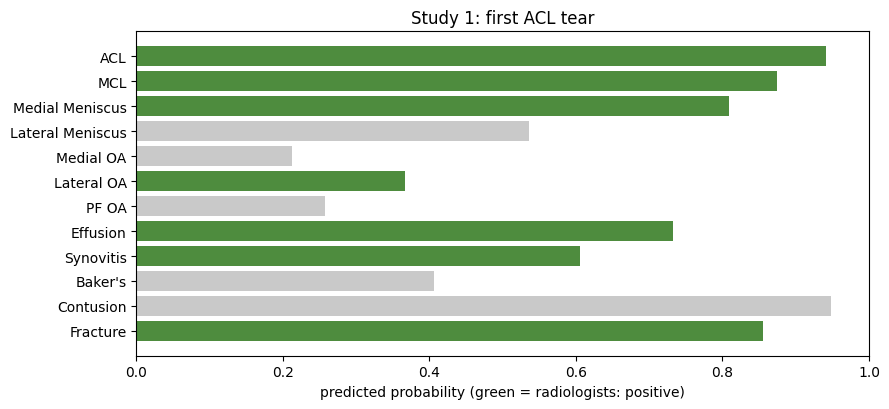

Where the model looked for ACL (predicted 0.94, radiologists: positive); top 4 of 44 windows = 44% of the attention


,slot,slice,attention
0,Sagittal FS,14,0.147
1,Sagittal FS,15,0.139
2,Sagittal FS,13,0.090
3,Sagittal FS,8,0.067


In [5]:
name = list(chosen)[0]; results[name] = run_study(chosen[name]); show(results[name], name)

## 5. Study 2: first medial OA without ACL tear

Study 2: first medial OA without ACL tear
9 series, 295 DICOM slices -> decoded in 0.5 s; 54 windows; both checkpoints 0.15 s


,plane,fluid-sensitive,slices
0,Sagittal,1,30
1,Coronal,0,35
2,Coronal,0,35
3,Coronal,1,35
4,Sagittal,0,30
5,Axial,0,40
6,Axial,1,40
7,Coronal,1,20
8,Sagittal,0,30


,probability,radiologists
ACL,0.752,-
MCL,0.596,-
Medial Meniscus,0.807,positive
Lateral Meniscus,0.427,positive
Medial OA,0.824,positive
Lateral OA,0.590,positive
PF OA,0.737,positive
Effusion,0.985,positive
Synovitis,0.762,positive
Baker's,0.986,positive


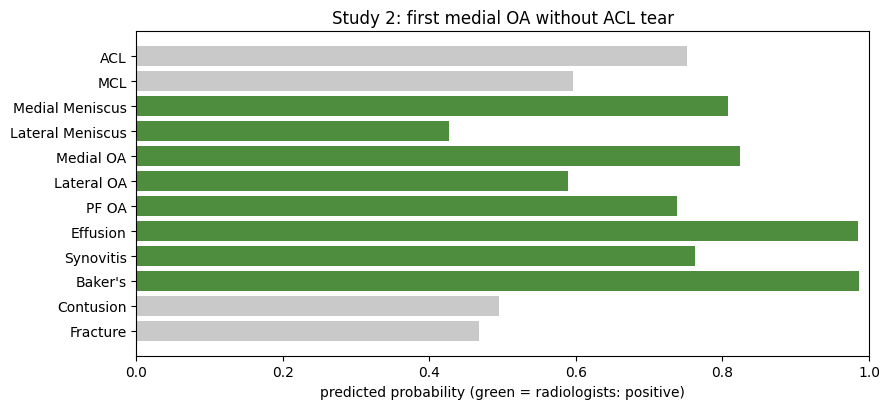

Where the model looked for Baker's (predicted 0.99, radiologists: positive); top 4 of 54 windows = 43% of the attention


,slot,slice,attention
0,Sagittal FS,5,0.122
1,Axial,8,0.103
2,Sagittal FS,6,0.103
3,Axial,6,0.097


In [6]:
name = list(chosen)[1]; results[name] = run_study(chosen[name]); show(results[name], name)

## 6. Study 3: first study with at most one finding

Study 3: first study with at most one finding
6 series, 114 DICOM slices -> decoded in 0.5 s; 54 windows; both checkpoints 0.15 s


,plane,fluid-sensitive,slices
0,Coronal,1,18
1,Axial,1,12
2,Sagittal,1,22
3,Coronal,0,18
4,Axial,1,22
5,Sagittal,0,22


,probability,radiologists
ACL,0.090,-
MCL,0.282,-
Medial Meniscus,0.118,-
Lateral Meniscus,0.293,-
Medial OA,0.086,-
Lateral OA,0.252,-
PF OA,0.325,positive
Effusion,0.001,-
Synovitis,0.289,-
Baker's,0.041,-


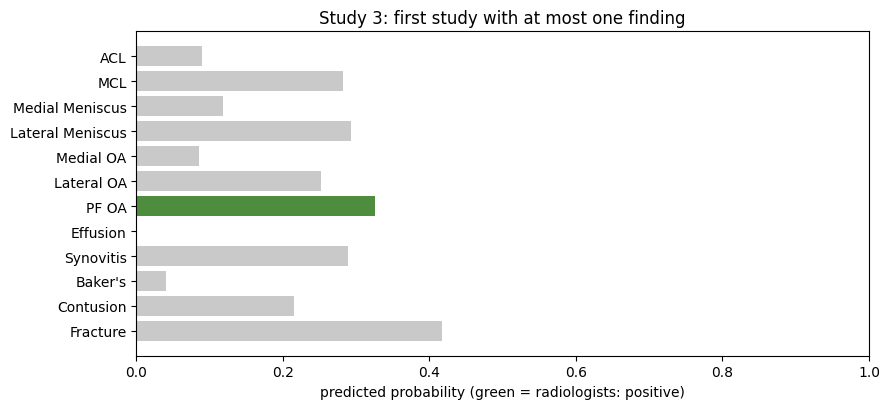

Where the model looked for PF OA (predicted 0.33, radiologists: positive); top 4 of 54 windows = 13% of the attention


,slot,slice,attention
0,Axial,11,0.034
1,Sagittal FS,10,0.034
2,Sagittal FS,12,0.033
3,Axial,10,0.033


In [7]:
name = list(chosen)[2]; results[name] = run_study(chosen[name]); show(results[name], name)

## 7. Summary

In [8]:
summary = pd.DataFrame({n.split(":")[0]: [f"{p:.2f}" + (" *" if g else "") for p, g in zip(r["prob"], r["gold"])]
                        for n, r in results.items()}, index=T)
print("* = radiologists: positive. Probabilities are ranking scores; the competition metric is macro ROC-AUC.")
display(summary)

* = radiologists: positive. Probabilities are ranking scores; the competition metric is macro ROC-AUC.


,Study 1,Study 2,Study 3
ACL,0.94 *,0.75,0.09
MCL,0.87 *,0.60,0.28
Medial Meniscus,0.81 *,0.81 *,0.12
Lateral Meniscus,0.54,0.43 *,0.29
Medial OA,0.21,0.82 *,0.09
Lateral OA,0.37 *,0.59 *,0.25
PF OA,0.26,0.74 *,0.33 *
Effusion,0.73 *,0.99 *,0.00
Synovitis,0.61 *,0.76 *,0.29
Baker's,0.41,0.99 *,0.04


**Reading the results.** Study 1's ligament and meniscus findings rank high, with attention on the central
sagittal fat-suppressed slices; its contusion score is a false positive. Study 3 is a mostly normal knee: every score
is low, including patellofemoral OA, which the radiologists called positive. That is a miss, of the kind our label
analysis predicts (report-derived training labels miss mild positives).

In the competition this exact code ran offline on Kaggle on about 1,300 hidden studies: about 20 minutes on 2 × T4
for this 2-checkpoint model; our main 10-checkpoint submission scored 0.912 private macro-AUC.